In [1]:
# license_analysis.py (Jupyter-friendly version)

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pymongo import MongoClient

# MongoDB setup
MONGO_URI = "mongodb://localhost:27017/"
DB_NAME = "validation_db"
COLLECTION_NAME = "document_validations"
import os

output_dir = "./figures_tables/license_validation_output"
os.makedirs(output_dir, exist_ok=True)

# 📥 Load data from MongoDB
client = MongoClient(MONGO_URI)
collection = client[DB_NAME][COLLECTION_NAME]

projection = {
    "_id": 1,
    "validation_info.checks.license_validation.status": 1,
    "validation_info.checks.license_validation.metrics.resolved_license": 1,
    "validation_info.checks.license_validation.metrics.license_source": 1,
    "validation_info.checks.license_validation.metrics.license_conflict": 1,
    "validation_info.checks.license_validation.metrics.input_licenses.crossref": 1,
    "validation_info.checks.license_validation.metrics.input_licenses.unpaywall": 1,
    "validation_info.checks.license_validation.metrics.input_licenses.openalex": 1
}

cursor = collection.find({}, projection)
data = list(cursor)
client.close()

df = pd.json_normalize(data)
df.rename(columns={
    "validation_info.checks.license_validation.status": "status",
    "validation_info.checks.license_validation.metrics.resolved_license": "resolved_license",
    "validation_info.checks.license_validation.metrics.license_source": "license_source",
    "validation_info.checks.license_validation.metrics.license_conflict": "license_conflict",
    "validation_info.checks.license_validation.metrics.input_licenses.crossref": "crossref_license",
    "validation_info.checks.license_validation.metrics.input_licenses.unpaywall": "unpaywall_license",
    "validation_info.checks.license_validation.metrics.input_licenses.openalex": "openalex_license",
}, inplace=True)

print(f"✅ Loaded {len(df)} documents")

✅ Loaded 582683 documents


In [ ]:
# 📋 License Conflict Summary Table
conflict_counts = df["license_conflict"].value_counts()
labels = conflict_counts.index.map({False: "No Conflict", True: "Conflict"})
conflict_counts.index = labels

# Calculate percentages
conflict_percentages = (conflict_counts / conflict_counts.sum()) * 100

# Create summary table
conflict_summary_df = pd.DataFrame({
    "Count": conflict_counts,
    "Percentage": conflict_percentages.map("{:.1f}%".format)
})

# Save to CSV
conflict_summary_df.to_csv(os.path.join(output_dir, "license_conflict_summary_table.csv"))

# Display the table in Jupyter
display(conflict_summary_df)


,Count,Percentage
license_conflict,,
No Conflict,582683,100.0%


/tmp/ipykernel_1700534/3891903745.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


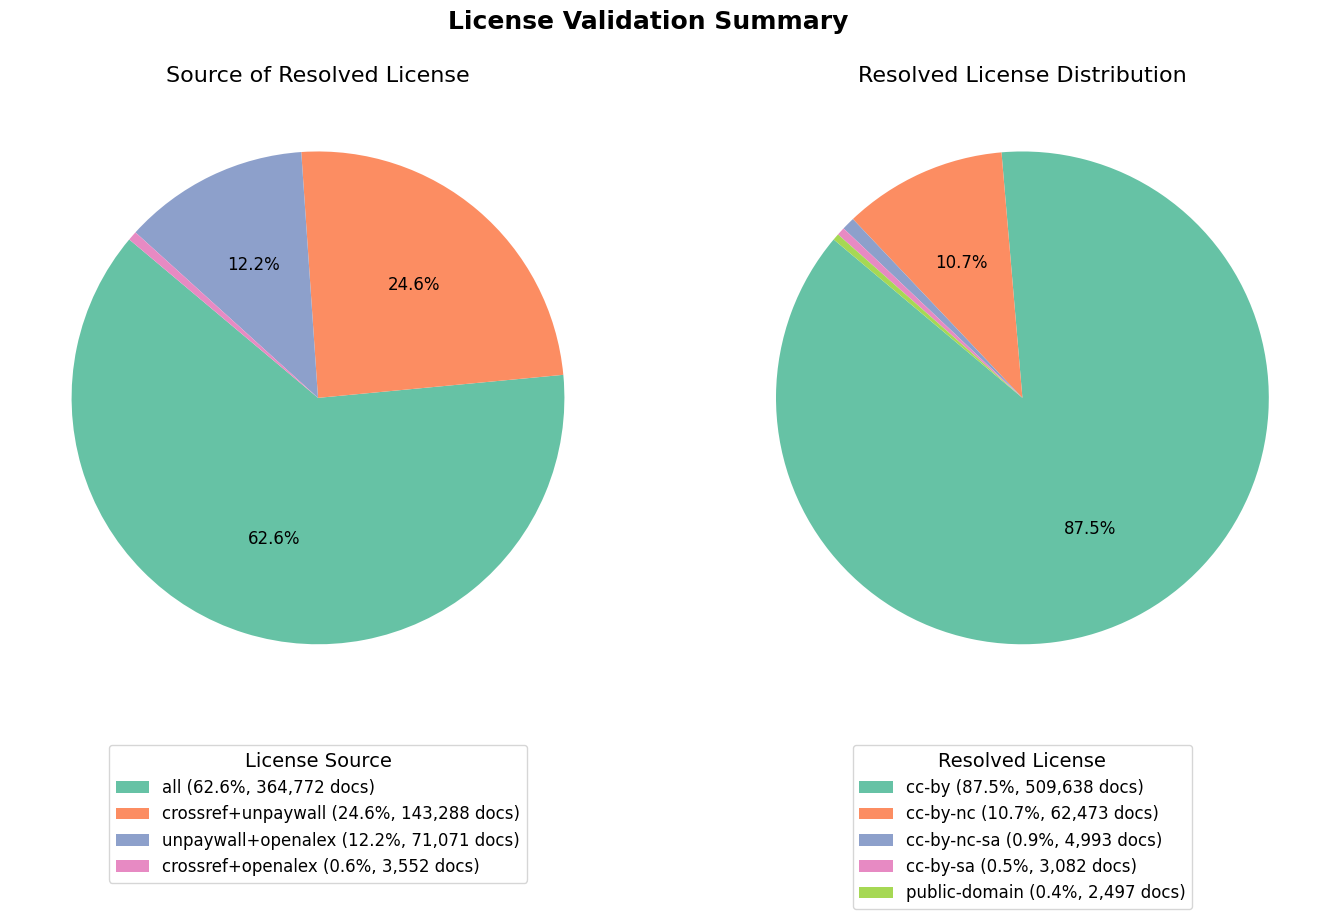

In [3]:
# 📊 Combined Pie Charts with Matching Contrastive Palette: License Validation Summary
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ---------- global font settings ----------
plt.rcParams.update({
    'font.size': 14,         # Default text
    'axes.titlesize': 16,    # Axes titles
    'axes.labelsize': 14,    # X/Y labels
    'xtick.labelsize': 12,   # X-ticks
    'ytick.labelsize': 12,   # Y-ticks
    'legend.fontsize': 12,   # Legend
    'figure.titlesize': 18   # Figure title
})

# ---------- data prep ----------
license_source_counts = df["license_source"].value_counts()
source_sizes = license_source_counts.values
source_labels = [
    f"{lab} ({cnt/source_sizes.sum():.1%}, {cnt:,} docs)"
    for lab, cnt in zip(license_source_counts.index, source_sizes)
]

license_counts = df["resolved_license"].value_counts()
sizes = license_counts.values
total = sizes.sum()
license_labels = [
    f"{lab} ({cnt/total:.1%}, {cnt:,} docs)"
    for lab, cnt in zip(license_counts.index, sizes)
]

# Contrastive palette
common_palette = sns.color_palette("Set2")

# ---------- figure ----------
fig, axes = plt.subplots(
    1, 2, figsize=(18, 8),
    gridspec_kw={"wspace": 0.02}  # closer spacing
)
fig.suptitle("License Validation Summary", fontweight="bold")

# Pie 1 ─ License Source
axes[0].pie(
    source_sizes, startangle=140,
    colors=common_palette[:len(source_sizes)],
    autopct=lambda p: f"{p:.1f}%" if p > 1 else "",
    textprops={'fontsize': 12}
)
axes[0].set_title("Source of Resolved License")
axes[0].legend(
    title="License Source", labels=source_labels,
    loc="upper center", bbox_to_anchor=(0.5, -0.05),
    ncol=1
)

# Pie 2 ─ Resolved License
axes[1].pie(
    sizes, startangle=140,
    colors=common_palette[:len(sizes)],
    autopct=lambda p: f"{p:.1f}%" if p > 1 else "",
    textprops={'fontsize': 12}
)
axes[1].set_title("Resolved License Distribution")
axes[1].legend(
    title="Resolved License", labels=license_labels,
    loc="upper center", bbox_to_anchor=(0.5, -0.05),
    ncol=1
)

# Layout & save
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(
    os.path.join(output_dir, "combined_pie_license_distribution_close.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()


In [4]:
# 📋 License Validation Status Summary Table
status_counts = df["status"].value_counts()
status_percentages = (status_counts / status_counts.sum()) * 100

# Create summary table
status_summary_df = pd.DataFrame({
    "Count": status_counts,
    "Percentage": status_percentages.map("{:.1f}%".format)
})

# Save to CSV
status_summary_df.to_csv(os.path.join(output_dir, "license_validation_status_summary_table.csv"))

# Display in notebook
display(status_summary_df)


,Count,Percentage
status,,
pass,582683,100.0%


In [5]:
# 📋 Extract only failed license validation files
failed_df = df[df["status"] == "fail"].copy()

# Save failed file details to CSV
failed_csv_path = os.path.join(output_dir, "failed_license_validation_files.csv")
failed_df.to_csv(failed_csv_path, index=False)

print(f"✅ Saved {len(failed_df)} failed license validation records to {failed_csv_path}")


✅ Saved 0 failed license validation records to ./figures_tables/license_validation_output/failed_license_validation_files.csv


In [6]:
# 📋 Extract records with license conflicts
conflict_df = df[df["license_conflict"] == True].copy()

# Save conflict report to CSV
conflict_csv_path = os.path.join(output_dir, "license_conflict_files.csv")
conflict_df.to_csv(conflict_csv_path, index=False)

print(f"✅ Saved {len(conflict_df)} license conflict records to {conflict_csv_path}")


✅ Saved 0 license conflict records to ./figures_tables/license_validation_output/license_conflict_files.csv
